# Random motion, conservation and diffusion

**Source mapping:** Vercauteren, Simulation and Modelling 2 (9 July 2025), §3.1–3.2, pp. 15–18.

Independent study companion; explanations and experiments are newly written. Read in the README order.

## Model and reasoning

A symmetric random walk has zero mean displacement and variance proportional to time. In the diffusion limit, $\mathrm{Var}(X)=2Dt$. Fick's flux is $J=-D\partial_x c$; conservation $\partial_t c+\partial_x J=0$ yields $\partial_t c=D\partial_{xx}c$ for constant D.

On the infinite line, a unit point mass has similarity solution $c(x,t)=(4\pi Dt)^{-1/2}\exp[-x^2/(4Dt)]$, t>0. Width grows like square-root time while height decreases; total mass remains one. This is not the solution for arbitrary finite-domain boundary conditions.

## Reproducible experiment

Predict the plot before running. All parameters below are illustrative, not measured environmental data.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True})
rng = np.random.default_rng(42)

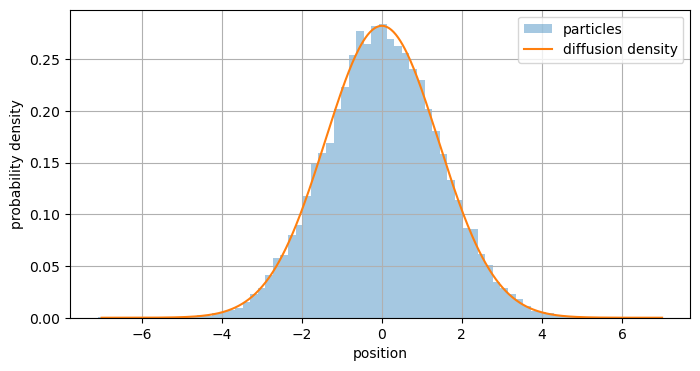

Observed variance / theoretical variance: 1.012409187453807


In [2]:
D=.5;dt=.01;n=200;walkers=20000
x=np.zeros(walkers)
for _ in range(n): x+=rng.normal(0,np.sqrt(2*D*dt),walkers)
t=n*dt;grid=np.linspace(-7,7,500)
p=np.exp(-grid**2/(4*D*t))/np.sqrt(4*np.pi*D*t)
plt.hist(x,bins=70,density=True,alpha=.4,label="particles");plt.plot(grid,p,label="diffusion density")
plt.xlabel("position");plt.ylabel("probability density");plt.legend();plt.show()
print("Observed variance / theoretical variance:",x.var()/(2*D*t))
assert abs(x.var()/(2*D*t)-1)<.05
assert abs(np.trapezoid(p,grid)-1)<.001

## Read the result

The histogram approaches the continuum density statistically. A finite sample is noisy; a random seed makes the demonstration reproducible without eliminating sampling error.

## Your turn

Repeat with 500 particles. Compare sampling noise with the deterministic discretisation errors from the previous layer.

Record: prediction → observation → explanation. A successful assertion checks this example; it is not a general proof.